# train_models.ipynb: Handwritten Digit Classification (5 models)

**Dataset:** Optical Recognition of Handwritten Digits (UCI ML Repository, bundled with scikit-learn): 1,797 images of 8x8 pixels, 10 classes (digits 0-9).

| Requirement | This notebook |
|---|---|
| Min. features / instances | 12 / 500 (this dataset: **64 / 1,797**) |
| Problem type | **Multi-class** (10 classes) |
| Models | Logistic Regression, Decision Tree, KNN, Gaussian Naive Bayes, SVM |
| Metrics | Accuracy, AUC (one-vs-rest, weighted), Precision, Recall, F1 (weighted), MCC |

Outputs used by the Streamlit app (`streamlit_app.py`): `test_data.csv`, `model/*.pkl`, `model/meta.json`.

## 1. Imports

In [1]:
import json, os, warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score, recall_score,
                             f1_score, matthews_corrcoef, confusion_matrix, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
SEED = 42
sns.set_theme(style="whitegrid")

## 2. Load the dataset
Each row is one 8x8 image flattened into 64 pixel intensities (0-16). The target column is renamed `digit`.

In [2]:
raw = load_digits(as_frame=True)
df = raw.frame.rename(columns={"target": "digit"})
TARGET = "digit"
print(f"Instances: {df.shape[0]} | Features: {df.shape[1] - 1} | Classes: {df[TARGET].nunique()} | Missing: {int(df.isna().sum().sum())}")
df.head()

Instances: 1797 | Features: 64 | Classes: 10 | Missing: 0
,

,pixel_0_0,pixel_0_1,pixel_0_2,pixel_0_3,pixel_0_4,pixel_0_5,pixel_0_6,pixel_0_7,pixel_1_0,pixel_1_1,pixel_1_2,pixel_1_3,pixel_1_4,pixel_1_5,pixel_1_6,pixel_1_7,pixel_2_0,pixel_2_1,pixel_2_2,pixel_2_3,pixel_2_4,pixel_2_5,pixel_2_6,pixel_2_7,pixel_3_0,pixel_3_1,pixel_3_2,pixel_3_3,pixel_3_4,pixel_3_5,pixel_3_6,pixel_3_7,pixel_4_0,pixel_4_1,pixel_4_2,pixel_4_3,pixel_4_4,pixel_4_5,pixel_4_6,pixel_4_7,pixel_5_0,pixel_5_1,pixel_5_2,pixel_5_3,pixel_5_4,pixel_5_5,pixel_5_6,pixel_5_7,pixel_6_0,pixel_6_1,pixel_6_2,pixel_6_3,pixel_6_4,pixel_6_5,pixel_6_6,pixel_6_7,pixel_7_0,pixel_7_1,pixel_7_2,pixel_7_3,pixel_7_4,pixel_7_5,pixel_7_6,pixel_7_7,digit
0,0.0,0.0,5.0,13.0,9.0,1.0,0.0,0.0,0.0,0.0,13.0,15.0,10.0,15.0,5.0,0.0,0.0,3.0,15.0,2.0,0.0,11.0,8.0,0.0,0.0,4.0,12.0,0.0,0.0,8.0,8.0,0.0,0.0,5.0,8.0,0.0,0.0,9.0,8.0,0.0,0.0,4.0,11.0,0.0,1.0,12.0,7.0,0.0,0.0,2.0,14.0,5.0,10.0,12.0,0.0,0.0,0.0,0.0,6.0,13.0,10.0,0.0,0.0,0.0,0
1,0.0,0.0,0.0,12.0,13.0,5.0,0.0,0.0,0.0,0.0,0.0,11.0,16.0,9.0,0.0,0.0,0.0,0.0,3.0,15.0,16.0,6.0,0.0,0.0,0.0,7.0,15.0,16.0,16.0,2.0,0.0,0.0,0.0,0.0,1.0,16.0,16.0,3.0,0.0,0.0,0.0,0.0,1.0,16.0,16.0,6.0,0.0,0.0,0.0,0.0,1.0,16.0,16.0,6.0,0.0,0.0,0.0,0.0,0.0,11.0,16.0,10.0,0.0,0.0,1
2,0.0,0.0,0.0,4.0,15.0,12.0,0.0,0.0,0.0,0.0,3.0,16.0,15.0,14.0,0.0,0.0,0.0,0.0,8.0,13.0,8.0,16.0,0.0,0.0,0.0,0.0,1.0,6.0,15.0,11.0,0.0,0.0,0.0,1.0,8.0,13.0,15.0,1.0,0.0,0.0,0.0,9.0,16.0,16.0,5.0,0.0,0.0,0.0,0.0,3.0,13.0,16.0,16.0,11.0,5.0,0.0,0.0,0.0,0.0,3.0,11.0,16.0,9.0,0.0,2
3,0.0,0.0,7.0,15.0,13.0,1.0,0.0,0.0,0.0,8.0,13.0,6.0,15.0,4.0,0.0,0.0,0.0,2.0,1.0,13.0,13.0,0.0,0.0,0.0,0.0,0.0,2.0,15.0,11.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,12.0,12.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,10.0,8.0,0.0,0.0,0.0,8.0,4.0,5.0,14.0,9.0,0.0,0.0,0.0,7.0,13.0,13.0,9.0,0.0,0.0,3
4,0.0,0.0,0.0,1.0,11.0,0.0,0.0,0.0,0.0,0.0,0.0,7.0,8.0,0.0,0.0,0.0,0.0,0.0,1.0,13.0,6.0,2.0,2.0,0.0,0.0,0.0,7.0,15.0,0.0,9.0,8.0,0.0,0.0,5.0,16.0,10.0,0.0,16.0,6.0,0.0,0.0,4.0,15.0,16.0,13.0,16.0,1.0,0.0,0.0,0.0,0.0,3.0,15.0,10.0,0.0,0.0,0.0,0.0,0.0,2.0,16.0,4.0,0.0,0.0,4


## 3. Exploratory analysis

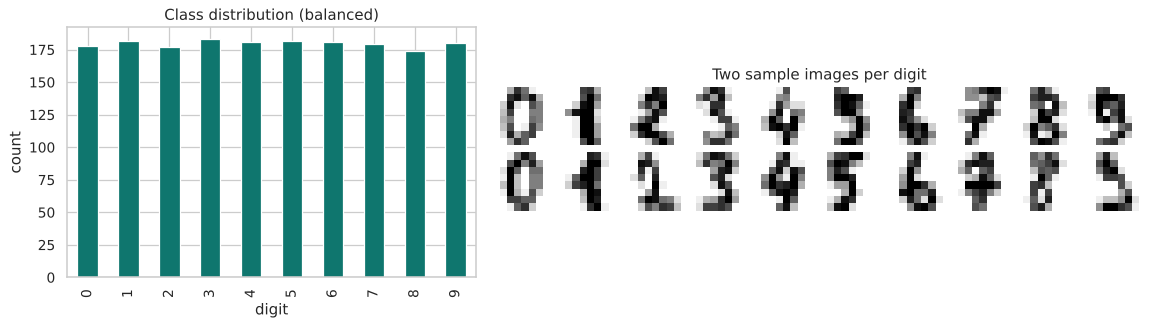

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1, 1.6]})
df[TARGET].value_counts().sort_index().plot.bar(ax=axes[0], color="#0f766e")
axes[0].set_title("Class distribution (balanced)"); axes[0].set_xlabel("digit"); axes[0].set_ylabel("count")
axes[1].axis("off")
grid = np.zeros((2 * 9, 10 * 9))
for d in range(10):
    for r in range(2):
        img = raw.images[np.where(raw.target == d)[0][r]]
        grid[r * 9:r * 9 + 8, d * 9:d * 9 + 8] = img
axes[1].imshow(grid, cmap="gray_r"); axes[1].set_title("Two sample images per digit")
plt.tight_layout(); plt.show()

## 4. Train / test split
Stratified 80/20 split so each digit appears in both sets in equal proportion. The test split (features + `digit`) is saved as `test_data.csv` for the app.

In [4]:
X, y = df.drop(columns=[TARGET]), df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
pd.concat([X_test, y_test], axis=1).to_csv("test_data.csv", index=False)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (1437, 64) | Test: (360, 64)
,

## 5. Define the five models
Logistic Regression, KNN and SVM are scale-sensitive, so a `StandardScaler` is part of their pipeline and is saved inside the `.pkl`.

In [5]:
models = {
    "Logistic Regression": Pipeline([("sc", StandardScaler()),
                                     ("m", LogisticRegression(max_iter=2000, random_state=SEED))]),
    "Decision Tree": DecisionTreeClassifier(max_depth=10, min_samples_leaf=2, random_state=SEED),
    "KNN": Pipeline([("sc", StandardScaler()), ("m", KNeighborsClassifier(n_neighbors=5))]),
    "Naive Bayes": GaussianNB(),
    "Support Vector Machine": Pipeline([("sc", StandardScaler()),
                                        ("m", SVC(kernel="rbf", C=1.0, probability=True, random_state=SEED))]),
}

def evaluate(model, X, y):
    pred, proba = model.predict(X), model.predict_proba(X)
    return {"Accuracy": accuracy_score(y, pred),
            "AUC": roc_auc_score(y, proba, multi_class="ovr", average="weighted"),
            "Precision": precision_score(y, pred, average="weighted", zero_division=0),
            "Recall": recall_score(y, pred, average="weighted", zero_division=0),
            "F1": f1_score(y, pred, average="weighted", zero_division=0),
            "MCC": matthews_corrcoef(y, pred)}

## 6. Train and evaluate

In [6]:
results = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    results[name] = evaluate(model, X_test, y_test)

results_df = pd.DataFrame(results).T.round(4)
results_df.style.highlight_max(axis=0, color="#bbf7d0").format("{:.4f}")

,Accuracy,AUC,Precision,Recall,F1,MCC
Logistic Regression,0.9722,0.9991,0.9724,0.9722,0.9722,0.9692
Decision Tree,0.8222,0.9157,0.8230,0.8222,0.8209,0.8028
KNN,0.9639,0.9951,0.9648,0.9639,0.9636,0.9600
Naive Bayes,0.8111,0.9707,0.8480,0.8111,0.8151,0.7940
Support Vector Machine,0.9750,0.9995,0.9759,0.9750,0.9749,0.9723


In [7]:
print(results_df.to_markdown())   # paste into README.md

|                        |   Accuracy |    AUC |   Precision |   Recall |     F1 |    MCC |
,|:-----------------------|-----------:|-------:|------------:|---------:|-------:|-------:|
,| Logistic Regression    |     0.9722 | 0.9991 |      0.9724 |   0.9722 | 0.9722 | 0.9692 |
,| Decision Tree          |     0.8222 | 0.9157 |      0.823  |   0.8222 | 0.8209 | 0.8028 |
,| KNN                    |     0.9639 | 0.9951 |      0.9648 |   0.9639 | 0.9636 | 0.96   |
,| Naive Bayes            |     0.8111 | 0.9707 |      0.848  |   0.8111 | 0.8151 | 0.794  |
,| Support Vector Machine |     0.975  | 0.9995 |      0.9759 |   0.975  | 0.9749 | 0.9723 |
,

## 7. Confusion matrices

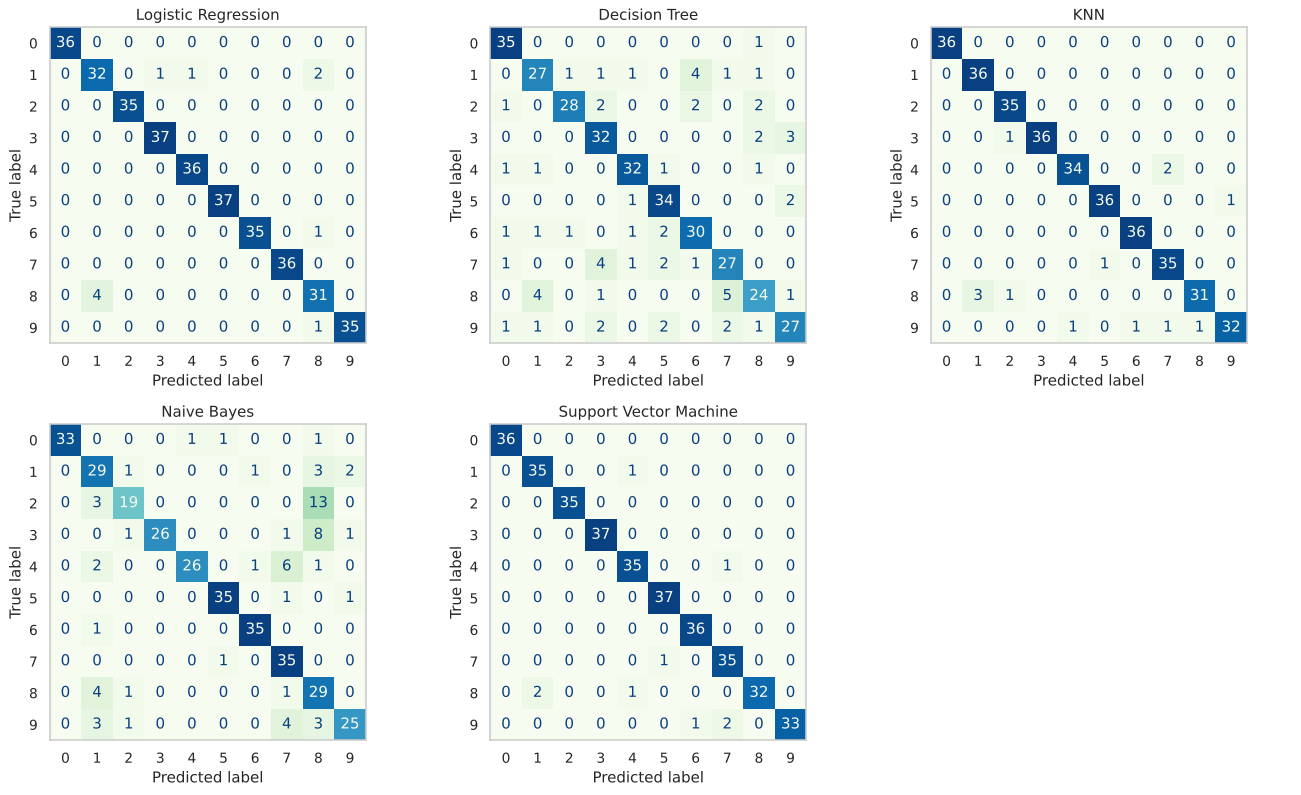

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, (name, model) in zip(axes.ravel(), models.items()):
    ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, ax=ax, cmap="GnBu", colorbar=False)
    ax.set_title(name); ax.grid(False)
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()

## 8. Metric comparison and most-confused digits

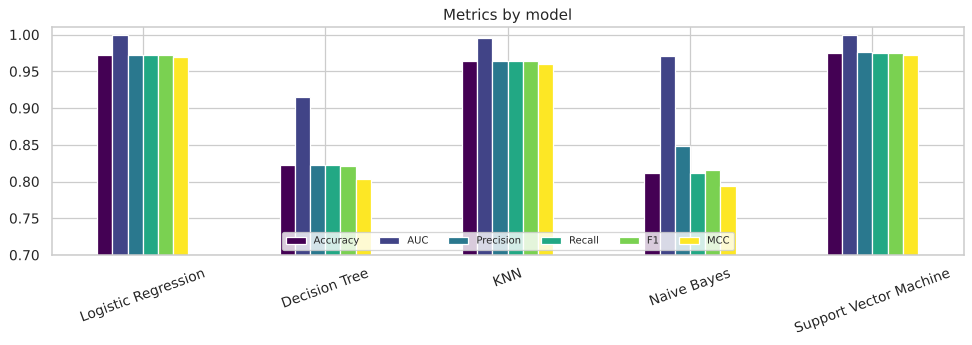

In [9]:
results_df.plot.bar(figsize=(11, 4), ylim=(0.7, 1.01), colormap="viridis")
plt.title("Metrics by model"); plt.xticks(rotation=20); plt.legend(ncol=6, fontsize=8, loc="lower center")
plt.tight_layout(); plt.show()

In [10]:
best = results_df["MCC"].idxmax()
cm = confusion_matrix(y_test, models[best].predict(X_test)); np.fill_diagonal(cm, 0)
pairs = sorted(((cm[i, j], i, j) for i in range(10) for j in range(10) if cm[i, j]), reverse=True)[:5]
print(f"Best model by MCC: {best}")
print("Most frequent mistakes (true -> predicted):", [(f"{i}->{j}", n) for n, i, j in pairs])

Best model by MCC: Support Vector Machine
,Most frequent mistakes (true -> predicted): [('9->7', np.int64(2)), ('8->1', np.int64(2)), ('9->6', np.int64(1)), ('8->4', np.int64(1)), ('7->5', np.int64(1))]
,

## 9. Save trained models and metadata
The Streamlit app loads these files; it never retrains.

In [11]:
os.makedirs("model", exist_ok=True)
for name, model in models.items():
    joblib.dump(model, f"model/{name.lower().replace(' ', '_')}.pkl")
json.dump({"target": TARGET, "features": list(X.columns), "classes": [int(c) for c in sorted(y.unique())],
           "metrics": results}, open("model/meta.json", "w"), indent=2)
sorted(os.listdir("model"))

['decision_tree.pkl', 'knn.pkl', 'logistic_regression.pkl', 'meta.json', 'naive_bayes.pkl', 'support_vector_machine.pkl']

## 10. Sanity check: reload saved models and score `test_data.csv`
Mirrors what the app does with an uploaded file.

In [12]:
test = pd.read_csv("test_data.csv")
Xt, yt = test.drop(columns=[TARGET]), test[TARGET]
check = {n: evaluate(joblib.load(f"model/{n.lower().replace(' ', '_')}.pkl"), Xt, yt) for n in models}
pd.DataFrame(check).T.round(4)

,Accuracy,AUC,Precision,Recall,F1,MCC
Logistic Regression,0.9722,0.9991,0.9724,0.9722,0.9722,0.9692
Decision Tree,0.8222,0.9157,0.8230,0.8222,0.8209,0.8028
KNN,0.9639,0.9951,0.9648,0.9639,0.9636,0.9600
Naive Bayes,0.8111,0.9707,0.8480,0.8111,0.8151,0.7940
Support Vector Machine,0.9750,0.9995,0.9759,0.9750,0.9749,0.9723


## 11. Observations

| Model | Observation |
|---|---|
| Logistic Regression | Very strong (~97% accuracy). Pixel intensities give a nearly linear separation between digits, and scaling helps convergence. |
| Decision Tree | Much weaker (~82%). Axis-aligned splits on individual pixels cannot capture stroke shapes, so it confuses similar digits. |
| KNN | Strong (~96%) because similar digits are close in pixel space; cost is slow prediction and dependence on scaling and k. |
| Naive Bayes | Weakest on accuracy (~81%): neighbouring pixels are heavily correlated, violating the independence assumption. AUC still high (~0.97) as ranking of class probabilities is decent. |
| Support Vector Machine | Best on every metric (~97.5% accuracy, MCC ~0.97); the RBF kernel models non-linear stroke patterns well. |
| **Winner** | Support Vector Machine, narrowly ahead of Logistic Regression. |